# Can quiz scores help plan refresher training?

*Research notebook · Frontline health worker training · Fully synthetic data*

## Executive summary

Frontline health workers may train in several batches, but early refresher slots can be limited. This prototype asks whether information already available after training can help a training team plan follow-up, and whether two optional questions about what workers were thinking during practice add enough value to collect.

**What we found in simulation:** Quiz scores provided a useful starting point. Thought reports made forecasts slightly worse on average when the simulation gave them no direct link to later scores. When a link was deliberately built in, they reduced the average miss by **0.13 percentage points** across 50 runs and helped in **40 of 50**. Forecast-guided scheduling beat a lottery only in the scenario where earlier refreshers were assumed to help lower-scoring batches more. The simpler rule—ranking batches by their immediate post-test averages—selected the same two batches as the forecast model. It matched the model’s outcomes in all three scenarios, so the model added no scheduling value in this example. Neither rule saved delivery time.

| Question | Key result |
| --- | --- |
| Do thought reports improve delayed-score forecasts? | Only slightly when a signal is built in. |
| Does the forecast improve early-slot allocation? | The simpler post-test rule chose the same batches. |
| Does a second data stream help? | Simulated gaze helped when it carried relevant information. |

---

## Model objective and possible uses

**Objective:** After the initial training and practice, estimate a worker’s score on a later quiz taken **before any refresher**. Test the forecast on whole batches the model hasn’t seen. For scheduling, average the forecasts within each batch and use that average to explore which batches could be offered the limited early slots.

**Possible use:** A training coordinator could use batch forecasts to plan follow-up capacity or compare ways of allocating early slots in a pilot. The model does not measure clinical competence, diagnose inattention, or identify who will benefit from going earlier. Real validation is needed before using forecasts to change anyone’s training schedule.

## Why test reports of mind wandering?

Mind wandering means thinking about something unrelated to the task, such as an errand during a practice question. Thinking about how the question applies to your work is still task-related. A thought probe asks what someone was thinking at one moment; it is not an attention score.

Prior research motivates the measurement method. [Mrazek and colleagues](https://pmc.ncbi.nlm.nih.gov/articles/PMC4796033/) used thought probes during a reading assessment. [Bühler and colleagues](https://doi.org/10.1037/edu0000903) studied mind wandering and learning during video lectures. Neither study shows that two optional prompts during workplace practice can predict retention or guide refresher timing.

**What we test:** We use synthetic data to demonstrate how we would test whether brief thought reports improve delayed-quiz forecasts beyond pre- and post-test scores in new training batches. Our prompts are asked during practice **after** the initial training, so they don’t tell us what workers were thinking during the lesson. The model predicts a later quiz score, not mind wandering. The scheduling example uses quiz scores alone.

## How to read and run this notebook

1. **Measurement:** Explore what workers report thinking during practice, and what skipped responses can hide.
2. **Forecasting:** Compare simple rules and models on new batches. The main comparison loads the bundled CSV; extra simulations test whether the result repeats.
3. **Scheduling:** Compare four scheduling rules: usual timing, a lottery for early slots, ranking by forecasts, and ranking by immediate post-test averages.

A **batch** is a group trained together. All records are fictional. The phases use separate datasets, so a worker ID in one phase is not the same person in another. The scheduling example uses quiz scores only, not thought reports.

To reproduce: keep `dummy_training_data.csv` beside this notebook. Install the packages with `python -m pip install -r requirements.txt`, then open the notebook from the project folder and choose **Restart Kernel and Run All Cells**. You can also read the saved charts and results without running anything.

## Phase 1: What can an optional check-in tell us?

A **thought probe** is a short question like “Just before you submitted your answer, what were you thinking about?” It appears after a practice answer and before feedback, not during the scored quiz. A worker might report thinking about the task, thinking about something unrelated, or being interrupted. They can say they’re unsure or skip.

We compare reports across groups with different immediate post-test scores. A report is a snapshot of one moment, not a rating of someone’s attention or proof that their thoughts caused a score difference.

### 1. How the fictional data were made

The simulation creates 192 workers in eight batches. Each has a pre-test, an immediate post-test, and two optional practice prompts. Prompt positions are chosen without looking at scores or answer correctness. The code assumes that workers’ starting preparation can influence **both** quiz scores and how often they report unrelated thoughts. That means a pattern can appear without unrelated thoughts causing lower scores. Batches can also differ in scores and interruptions. The default assumes no selective skipping; this phase also tries a version where unrelated thoughts are more likely to go unreported.

In [1]:
from random import Random


def simulate(seed=42, skip_bias=0.0, thought_link=0.06):
    rng = Random(seed)
    workers, probes = [], []
    for batch in range(1, 9):
        batch_score = rng.uniform(-5, 5)
        interruption_rate = rng.uniform(0.04, 0.20)
        for _ in range(24):
            worker_id = len(workers) + 1
            preparation = rng.uniform(-2, 2)
            pre = round(min(100, max(0, 65 + 12 * preparation + rng.gauss(0, 8))))
            post = round(min(100, max(0, 78 + 12 * preparation + batch_score + rng.gauss(0, 8))))
            workers.append(dict(worker=worker_id, batch=batch, pre=pre, post=post))
            for item in sorted(rng.sample(range(2, 10), 2)):
                draw = rng.random()
                unrelated_rate = 0.23 - thought_link * preparation
                if draw < interruption_rate:
                    response = 'interrupted'
                elif draw < interruption_rate + unrelated_rate:
                    response = 'unrelated'
                else:
                    response = 'task-related'
                skip_rate = 0.12 + (skip_bias if response == 'unrelated' else 0)
                skip_draw, unsure_draw = rng.random(), rng.random()
                if skip_draw < skip_rate:
                    response = 'skipped'
                elif unsure_draw < 0.05:
                    response = 'unsure'
                probes.append(dict(worker=worker_id, item=item, response=response))
    return workers, probes


workers, probes = simulate()
assert len({row['worker'] for row in workers}) == len(workers) == 192
assert len({(row['worker'], row['item']) for row in probes}) == len(probes) == 384
assert all(0 <= row['pre'] <= 100 and 0 <= row['post'] <= 100 for row in workers)
print(f'{len(workers)} workers, {len(probes)} prompts shown, 8 batches')

192 workers, 384 prompts shown, 8 batches


### 2. How to read the score bands

A band such as **70–84%** means 70–84% of quiz questions were answered correctly, not that the worker ranked in that percentile range. The reported rate is **unrelated-thought responses ÷ all clear responses**. External interruptions count as clear responses but not unrelated thoughts. Skips and unsure responses are shown separately. One worker can contribute two reports, so these are counts of responses, not counts of people.

In [2]:
from collections import Counter

BANDS = ((0, 69), (70, 84), (85, 100))


def summarize(workers, probes, batch=None):
    print('Band     Workers  Shown  Usable  Skipped  Unsure  Interrupted  Unrelated  Rate')
    for low, high in BANDS:
        ids = {row['worker'] for row in workers
               if low <= row['post'] <= high and (batch is None or row['batch'] == batch)}
        counts = Counter(row['response'] for row in probes if row['worker'] in ids)
        shown = sum(counts.values())
        usable = shown - counts['skipped'] - counts['unsure']
        rate = f"{counts['unrelated'] / usable:.1%}" if usable else 'n/a'
        print(f'{low:2}-{high:<3} {len(ids):8} {shown:6} {usable:7} '
              f"{counts['skipped']:8} {counts['unsure']:7} {counts['interrupted']:12} "
              f"{counts['unrelated']:10}  {rate}")


summarize(workers, probes)
for batch in sorted({row['batch'] for row in workers}):
    print(f'\nBatch {batch}')
    summarize(workers, probes, batch=batch)

Band     Workers  Shown  Usable  Skipped  Unsure  Interrupted  Unrelated  Rate
 0-69        70    140     112       23       5           13         39  34.8%
70-84        64    128     104       19       5           13         17  16.3%
85-100       58    116      99       13       4           10         18  18.2%

Batch 1
Band     Workers  Shown  Usable  Skipped  Unsure  Interrupted  Unrelated  Rate
 0-69         9     18      12        5       1            0          5  41.7%
70-84         5     10       7        3       0            0          1  14.3%
85-100       10     20      17        2       1            0          2  11.8%

Batch 2
Band     Workers  Shown  Usable  Skipped  Unsure  Interrupted  Unrelated  Rate
 0-69        13     26      21        4       1            2         10  47.6%
70-84         5     10       9        0       1            0          1  11.1%
85-100        6     12      12        0       0            1          3  25.0%

Batch 3
Band     Workers  Shown  

In [3]:
print('Sensitivity check: unrelated thoughts are more likely to be skipped')
biased_workers, biased_probes = simulate(skip_bias=0.30)
assert biased_workers == workers
summarize(biased_workers, biased_probes)

print('\nSensitivity check: remove the preparation-to-thought link')
unlinked_workers, unlinked_probes = simulate(thought_link=0)
assert unlinked_workers == workers
summarize(unlinked_workers, unlinked_probes)

Sensitivity check: unrelated thoughts are more likely to be skipped
Band     Workers  Shown  Usable  Skipped  Unsure  Interrupted  Unrelated  Rate
 0-69        70    140     105       30       5           13         32  30.5%
70-84        64    128      99       24       5           13         12  12.1%
85-100       58    116      94       18       4           10         13  13.8%

Sensitivity check: remove the preparation-to-thought link
Band     Workers  Shown  Usable  Skipped  Unsure  Interrupted  Unrelated  Rate
 0-69        70    140     112       23       5           13         27  24.1%
70-84        64    128     104       19       5           13         14  13.5%
85-100       58    116      99       13       4           10         24  24.2%


**How far could skips move the result?** We calculate two extremes: none of the skipped prompts involved unrelated thoughts, or all of them did. In each case, skips are added to the total; unsure answers stay excluded. The line on the chart spans these what-if values, and the dot shows the rate among clear responses. The line is not a confidence interval.

In [4]:
bounds = []
for low, high in BANDS:
    ids = {row['worker'] for row in workers if low <= row['post'] <= high}
    counts = Counter(row['response'] for row in probes if row['worker'] in ids)
    denominator = sum(counts.values()) - counts['unsure']
    unrelated = counts['unrelated']
    lower = unrelated / denominator
    upper = (unrelated + counts['skipped']) / denominator
    assert 0 <= lower <= upper <= 1
    bounds.append((lower, upper))
    print(f'{low}-{high}% correct: {lower:.1%} to {upper:.1%}')

for (low, high), (_, upper) in zip(BANDS[1:], bounds[1:]):
    print(f'{low}-{high}% band could exceed the lowest band: {upper > bounds[0][0]}')

0-69% correct: 28.9% to 45.9%
70-84% correct: 13.8% to 29.3%
85-100% correct: 16.1% to 27.7%
70-84% band could exceed the lowest band: True
85-100% band could exceed the lowest band: False


## 3. Interpret the pilot

When unrelated thoughts are selectively skipped, some off-task moments disappear from both the numerator and the denominator. The observed rate can understate how often they occurred. Removing the simulated link shows how the apparent pattern can change without changing quiz scores. Small batch cells can fluctuate substantially; do not rank batches or workers from these counts.

**Interview decision record:** I kept reports separate from scores, sampled independently of correctness, and treated skips as missing rather than on-task. Phase 1 tests feasibility with real participants only if a pilot is actually run. Phase 2 would test whether probes improve delayed-score forecasts in unseen batches. Phase 3 would test whether changing refresher timing improves retention or saves time.

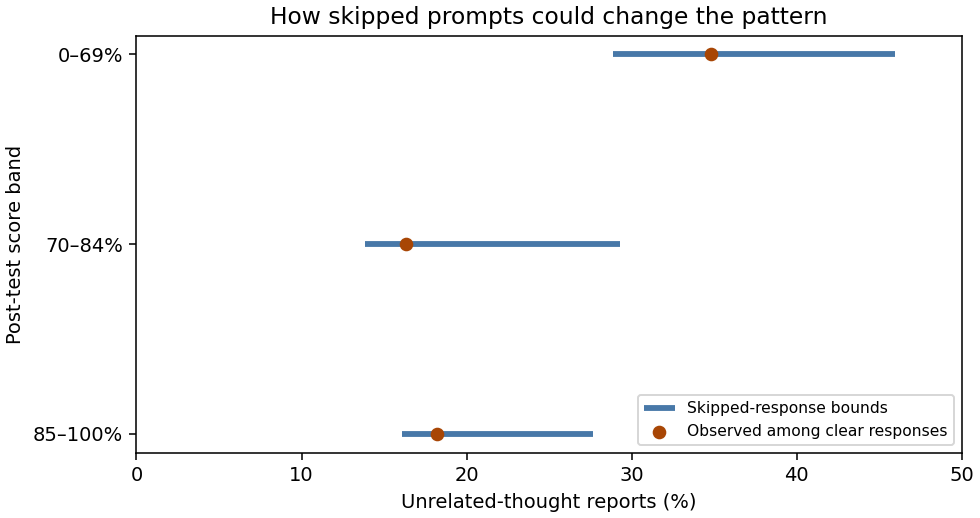

In [5]:
import matplotlib.pyplot as plt

band_labels = [f'{low}–{high}%' for low, high in BANDS]
observed = []
for low, high in BANDS:
    band_ids = {row['worker'] for row in workers if low <= row['post'] <= high}
    counts = Counter(row['response'] for row in probes if row['worker'] in band_ids)
    clear = sum(counts.values()) - counts['skipped'] - counts['unsure']
    observed.append(100 * counts['unrelated'] / clear)

fig, ax = plt.subplots(figsize=(7, 3.7), layout='constrained')
for index, ((lower, upper), rate) in enumerate(zip(bounds, observed, strict=True)):
    ax.hlines(index, 100 * lower, 100 * upper, color='#4878a8', linewidth=3,
              label='Skipped-response bounds' if index == 0 else None)
    ax.scatter(rate, index, color='#a84605', zorder=3,
               label='Observed among clear responses' if index == 0 else None)
ax.set(yticks=range(len(band_labels)), yticklabels=band_labels, xlim=(0, 50),
       xlabel='Unrelated-thought reports (%)', ylabel='Post-test score band',
       title='How skipped prompts could change the pattern')
ax.invert_yaxis()
ax.legend(loc='lower right', fontsize=8)
plt.show()

**Read the chart:** Dots show observed rates; lines show what skipped answers could change. These are what-if bounds, not confidence intervals.

## Phase 2A: Forecast delayed quiz scores with a simple baseline

**Question:** On entirely new training batches, how far off is the forecast if we assume each worker scores the same on the delayed quiz as on the immediate post-test?

All scores are simulated. The forecast is made immediately after training. The delayed quiz is taken later, before any refresher. We do not use thought probes or estimate anyone's attention.

## 1. Create a standalone benchmark

This is a separate synthetic dataset, not an extension of the Phase 1 worker records. Scores are percentages correct on comparable quizzes. The simulation assumes delayed scores are typically six points lower before adding batch differences and individual variation. Not everyone drops. Scores stay between 0 and 100. These assumptions shape the baseline error; it isn't a real estimate of knowledge loss. For this first benchmark, everyone completes both quizzes.

In [6]:
from random import Random
from statistics import mean


def simulate(seed=42, batches=8):
    rng = Random(seed)
    rows = []
    for batch in range(1, batches + 1):
        batch_change = rng.gauss(0, 3)
        for _ in range(24):
            post = round(min(100, max(0, rng.gauss(78, 14))))
            delayed = round(min(100, max(0, post - 6 + batch_change + rng.gauss(0, 8))))
            rows.append(dict(worker=len(rows) + 1, batch=batch, post=post, delayed=delayed))
    return rows


rows = simulate()
development = [row for row in rows if row['batch'] <= 6]
test = [row for row in rows if row['batch'] > 6]
development_batches = {row['batch'] for row in development}
test_batches = {row['batch'] for row in test}
assert development_batches.isdisjoint(test_batches)
assert {row['worker'] for row in development}.isdisjoint(row['worker'] for row in test)
assert len(development) + len(test) == len(rows) == 192
print(f'Development: {len(development)} workers in batches {sorted(development_batches)}')
print(f'Held out: {len(test)} workers in batches {sorted(test_batches)}')

Development: 144 workers in batches [1, 2, 3, 4, 5, 6]
Held out: 48 workers in batches [7, 8]


### How we score a forecast

If we predict 80% and the later score is 72%, the forecast is eight **percentage points** too high. If another prediction is eight points too low, the **mean absolute error (MAE)** is eight points: it counts the size of each miss. The **mean signed error** is zero: the high and low misses cancel. We report both because a forecast can be unbiased on average and still miss by a lot.

In [7]:
def evaluate(examples, adjustment=0):
    predictions = [min(100, max(0, row['post'] + adjustment)) for row in examples]
    errors = [prediction - row['delayed'] for prediction, row in zip(predictions, examples)]
    return mean(abs(error) for error in errors), mean(errors)


assert evaluate([{'post': 80, 'delayed': 72}, {'post': 80, 'delayed': 88}]) == (8, 0)
for batch in sorted(test_batches):
    batch_rows = [row for row in test if row['batch'] == batch]
    mae, bias = evaluate(batch_rows)
    print(f'Batch {batch} (n={len(batch_rows)}): MAE {mae:.2f}; signed error {bias:+.2f}')
mae, bias = evaluate(test)
print(f'Pooled (n={len(test)}): MAE {mae:.2f}; signed error {bias:+.2f} percentage points')

Batch 7 (n=24): MAE 5.29; signed error +3.04
Batch 8 (n=24): MAE 7.62; signed error +5.38
Pooled (n=48): MAE 6.46; signed error +4.21 percentage points


## 3. Interpret what this tells us

For two equal and opposite eight-point misses, this yields an MAE of eight points and a signed error of zero: the two misses cancel when direction is kept. The baseline does not learn from historical scores, so the development batches are set aside for later models. The two evaluated batches provide a worked example, not strong evidence about performance across training programmes. Their results are now visible; if we use them to guide model changes, we will need fresh batches for a final check.

**Interview decision record:** I chose a baseline that uses only information available at prediction time, checked for zero batch overlap, and reported both error size and direction. Future models should first show that quiz inputs alone can improve on this baseline. A useful forecast still does not show whether offering an earlier refresher improves retention.

## 4. Phase 2B: Learn a single adjustment

Average the delayed-minus-immediate score differences in development batches 1–6. Add that one adjustment to every later forecast and keep forecasts between 0 and 100. Compare both rules on fresh simulated batches 9–12; batches 7–8 are not used to fit or score this comparison.



In [8]:
expanded = simulate(batches=12)
assert expanded[:len(rows)] == rows
fresh = [row for row in expanded if row['batch'] > 8]
fresh_batches = {row['batch'] for row in fresh}
assert fresh_batches.isdisjoint(development_batches | test_batches)
assert {row['worker'] for row in fresh}.isdisjoint(row['worker'] for row in rows)
adjustment = mean(row['delayed'] - row['post'] for row in development)
print(f'Learned adjustment: {adjustment:+.2f} points')
print(f'An immediate score of 80 forecasts {min(100, max(0, 80 + adjustment)):.2f}')
print('Batch     Baseline MAE / signed error   Adjusted MAE / signed error')
for batch in [*sorted(fresh_batches), 'Pooled']:
    examples = fresh if batch == 'Pooled' else [row for row in fresh if row['batch'] == batch]
    baseline_mae, baseline_bias = evaluate(examples)
    adjusted_mae, adjusted_bias = evaluate(examples, adjustment)
    print(f'{batch!s:6} {baseline_mae:13.2f} / {baseline_bias:+.2f}'
          f'{adjusted_mae:22.2f} / {adjusted_bias:+.2f}')

Learned adjustment: -3.99 points
An immediate score of 80 forecasts 76.01
Batch     Baseline MAE / signed error   Adjusted MAE / signed error
9               9.33 / +9.08                  6.75 / +5.09
10             15.00 / +15.00                 11.42 / +11.01
11              6.38 / +4.96                  5.21 / +0.97
12             10.67 / +9.00                  8.84 / +5.01
Pooled         10.34 / +9.51                  8.06 / +5.52


A smaller average signed error can coexist with larger misses for some workers. Compare MAE overall and by batch rather than judging the change by bias alone. The simulation already builds in a typical drop, so this exercise tests the evaluation method, not whether real workers need an adjustment.

## Phase 2C — Predict delayed quiz scores in new training batches

**Forecast time:** after the initial training, immediate post-test and short practice block. **Target:** percentage correct on a later quiz, before any refresher. All workers, batches, scores and thought probes are synthetic. This is an offline forecasting prototype, not an LMS integration or a scheduling rule.

This standalone experiment compares a no-change baseline, the Phase 2B average adjustment, and three linear models. It uses fresh synthetic records rather than reusing the previous notebooks' test results.

### 1. What’s in the forecasting dataset?

The CSV has one row per fictional worker. Starting knowledge influences both quiz scores, batches can differ, and each worker has just two optional prompts. Everyone is assumed to complete the delayed quiz. The simulation also gives the pre-test a role in generating delayed scores, so a benefit from using it would not establish a real-world effect.

The CSV gives each worker two alternative delayed scores. Both scenarios use the same underlying records: in one, the worker’s hidden tendency to report unrelated thoughts has no direct effect on the delayed score; in the other, a stronger tendency is assumed to lower it. The model cannot see that hidden tendency. It sees only the two sampled reports and the quiz scores. We compare models separately in each scenario, using one delayed score at a time as the target. The generator below is retained so the CSV can be reproduced.

In [9]:
from collections import Counter
from random import Random
from statistics import mean

import numpy as np


def score(value):
    return round(min(100, max(0, value)))


def simulate(probe_signal, seed=510):
    rng = Random(seed)
    rows = []
    for batch in range(1, 21):
        training_shift = rng.gauss(0, 3)
        retention_shift = rng.gauss(0, 4)
        interruption_rate = rng.uniform(0.05, 0.18)
        for _ in range(24):
            preparation = rng.gauss(0, 1)
            propensity = rng.uniform(0.05, 0.60)
            pre = score(64 + 12 * preparation + rng.gauss(0, 8))
            post = score(78 + 10 * preparation + training_shift + rng.gauss(0, 8))
            delayed = score(
                0.8 * post + 0.2 * pre - 3 + retention_shift
                + rng.gauss(0, 7) - probe_signal * (propensity - 0.325)
            )
            responses = Counter()
            for _ in rng.sample(range(2, 10), 2):
                draw = rng.random()
                if draw < 0.12:
                    response = 'skipped'
                elif draw < 0.17:
                    response = 'unsure'
                elif draw < 0.17 + interruption_rate:
                    response = 'interrupted'
                elif draw < 0.17 + interruption_rate + propensity:
                    response = 'unrelated'
                else:
                    response = 'task-related'
                responses[response] += 1
            rows.append({
                'worker': len(rows) + 1, 'batch': batch,
                'pre': pre, 'post': post, 'delayed': delayed,
                'unrelated': responses['unrelated'],
                'interrupted': responses['interrupted'],
                'missing': responses['skipped'] + responses['unsure'],
            })
    return rows

### 2. How the models learn and how we test them

We fit models on **14 batches (336 workers)** and test all of them on the **same six unseen batches (144 workers)**. No worker or batch appears on both sides. Holding out a whole batch matches the intended question: can the model forecast for a new training group?

- **No change:** Copy the immediate post-test score.
- **Average adjustment:** Learn one average score change from the training batches and apply it to everyone.
- **Post only → Pre + post:** Let a linear model learn how much weight to give each score. Adding the pre-test asks whether knowing where workers started improves the forecast.
- **Pre + post → Quiz + probes:** Add the counts of unrelated thoughts, interruptions, and missed or uncertain answers. Two skipped prompts are not treated as two on-task reports.

The model never uses worker IDs, batch IDs, or either delayed score as an input. It learns from delayed results in the training batches, then uses only information available at forecast time for the test batches.

In [10]:
import csv
from pathlib import Path


def features(rows, columns):
    return [[row[column] for column in columns] for row in rows]


def design_matrix(rows, columns):
    values = np.array(features(rows, columns), dtype=float)
    return np.column_stack((np.ones(len(rows)), values))


def metrics(actual, forecast):
    errors = [min(100, max(0, prediction)) - observed
              for observed, prediction in zip(actual, forecast, strict=True)]
    return mean(abs(error) for error in errors), mean(errors)


assert metrics([72, 88], [80, 80]) == (8, 0)


def evaluate(rows):
    train = [row for row in rows if row['split'] == 'development']
    test = [row for row in rows if row['split'] == 'held_out']
    assert len(train) == 336 and len(test) == 144
    for key in ('batch', 'worker'):
        assert {row[key] for row in train}.isdisjoint(row[key] for row in test)
    actual = [row['delayed'] for row in test]
    post = [row['post'] for row in test]
    adjustment = mean(row['delayed'] - row['post'] for row in train)
    forecasts = {'No change': post,
                 'Average adjustment': [value + adjustment for value in post]}
    for label, columns in (
        ('Post only', ('post',)),
        ('Pre + post', ('pre', 'post')),
        ('Quiz + probes', ('pre', 'post', 'unrelated', 'interrupted', 'missing')),
    ):
        weights, *_ = np.linalg.lstsq(
            design_matrix(train, columns), [row['delayed'] for row in train], rcond=None
        )
        forecasts[label] = design_matrix(test, columns) @ weights

    print(f"{'Forecast':20} {'MAE':>6}  {'Signed error':>12}")
    for label, forecast in forecasts.items():
        mae, signed = metrics(actual, forecast)
        print(f'{label:20} {mae:6.2f}  {signed:+12.2f}')

    print('\nBatch     Pre + post MAE    Quiz + probes MAE')
    for batch in sorted({row['batch'] for row in test}):
        indices = [index for index, row in enumerate(test) if row['batch'] == batch]
        observed = [actual[index] for index in indices]
        quiz, combined = [
            metrics(observed, [forecasts[label][index] for index in indices])[0]
            for label in ('Pre + post', 'Quiz + probes')
        ]
        print(f'{batch:5} {quiz:18.2f} {combined:20.2f}')

    return {label: metrics(actual, forecast)[0] for label, forecast in forecasts.items()}


prediction_mae = {}
with Path('dummy_training_data.csv').open(encoding='utf-8', newline='') as stream:
    csv_rows = [
        {key: value if key == 'split' else int(value) for key, value in row.items()}
        for row in csv.DictReader(stream)
    ]
assert len(csv_rows) == len({row['worker'] for row in csv_rows}) == 480
assert Counter(row['batch'] for row in csv_rows) == dict.fromkeys(range(1, 21), 24)
assert all(row['split'] == ('development' if row['batch'] <= 14 else 'held_out')
           for row in csv_rows)

for signal, target in ((0, 'delayed_no_signal'), (24, 'delayed_with_signal')):
    print('\nScenario:', 'no direct probe signal' if signal == 0 else 'probe signal built in')
    prediction_mae[signal] = evaluate([{**row, 'delayed': row[target]} for row in csv_rows])


Scenario: no direct probe signal
Forecast                MAE  Signed error
No change              7.53         +5.34
Average adjustment     6.36         -1.12
Post only              6.40         -1.13
Pre + post             6.34         -1.36
Quiz + probes          6.45         -1.34

Batch     Pre + post MAE    Quiz + probes MAE
   15               6.96                 7.21
   16               5.78                 6.23
   17               5.64                 5.52
   18               7.81                 7.76
   19               6.77                 7.04
   20               5.10                 4.95

Scenario: probe signal built in
Forecast                MAE  Signed error
No change              7.59         +5.09
Average adjustment     6.86         -1.32
Post only              6.81         -1.33
Pre + post             6.74         -1.55
Quiz + probes          6.55         -1.38

Batch     Pre + post MAE    Quiz + probes MAE
   15               6.67                 7.03
   16        

## 3. Read the results

MAE is the average miss in percentage points. Signed error is forecast minus actual, so a positive value means forecasts run high. The meaningful comparisons use the same held-out workers within each scenario. A small pooled improvement can hide worse predictions in some batches. These batches are now visible; if you tune based on the results, use fresh batches for a final check.

**Interview takeaway:** I tested whether an extra measure improved predictions beyond scores alone, using whole unseen batches. The signal scenario deliberately builds in an association; it does not validate probes in real training. Two prompts are noisy, completion was assumed, and the six test batches illustrate the method rather than establish a reliable population estimate. To use this in practice we would need real delayed quiz outcomes, a missing-data check and a separate evaluation of whether changing refresher timing helps.

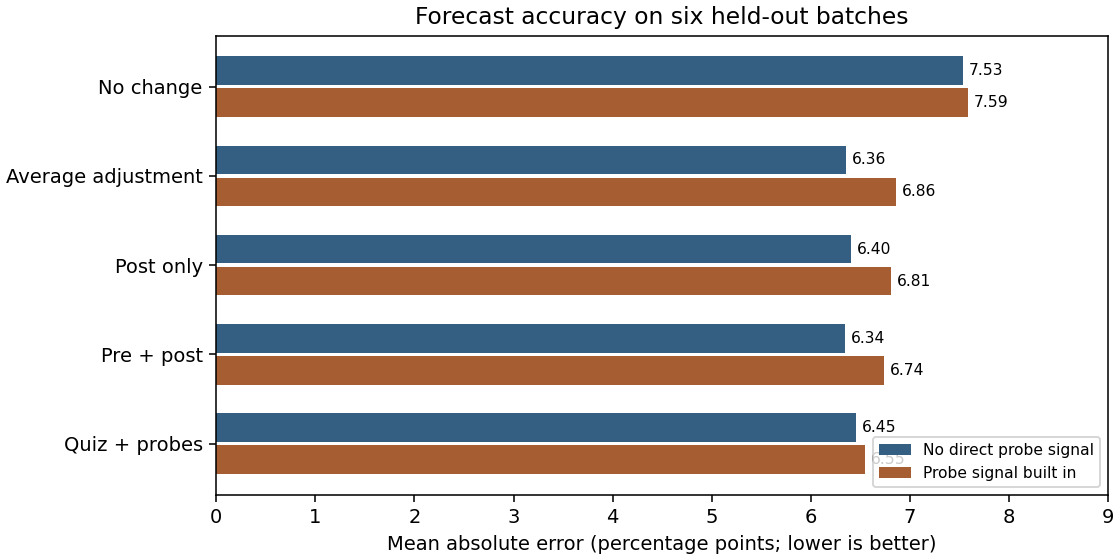

In [11]:
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
model_names = list(prediction_mae[0])
for offset, signal, label in [(-0.18, 0, 'No direct probe signal'),
                              (0.18, 24, 'Probe signal built in')]:
    values = [prediction_mae[signal][name] for name in model_names]
    bars = ax.barh([index + offset for index in range(len(model_names))],
                   values, height=0.32, label=label, color='#355f82' if signal == 0 else '#a65d31')
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=8)
ax.set(yticks=range(len(model_names)), yticklabels=model_names, xlim=(0, 9),
       xlabel='Mean absolute error (percentage points; lower is better)',
       title='Forecast accuracy on six held-out batches')
ax.invert_yaxis()
ax.legend(loc='lower right', fontsize=8)
plt.show()

**Read the chart:** Shorter bars mean smaller errors. Compare models within each scenario: thought probes add little beyond pre- and post-test scores.

## 4. Does the probe result repeat?

The bundled CSV is still the main worked example. As a sensitivity check, generate 50 fresh datasets per scenario (seeds 1000–1049). Pair the scenarios on the same random draws, refit on the first 14 batches each time, and compare the two models on the same six held-out batches. The difference is **quiz-plus-probes MAE minus quiz-only MAE**: negative means probes helped. The spread describes variation under this simulator, not uncertainty about real workers.

**Model limitation:** The forecasting robustness check assumes that skipping a probe does not depend on what the worker was thinking. Phase 1 showed how selective skipping can change descriptive rates, but we did not test its impact on forecast accuracy. More seeds under the same assumption cannot close that gap.

No direct probe signal: helped in 14/50 runs; mean change +0.037 points; range -0.123 to +0.234
Probe signal built in: helped in 40/50 runs; mean change -0.133 points; range -0.495 to +0.235


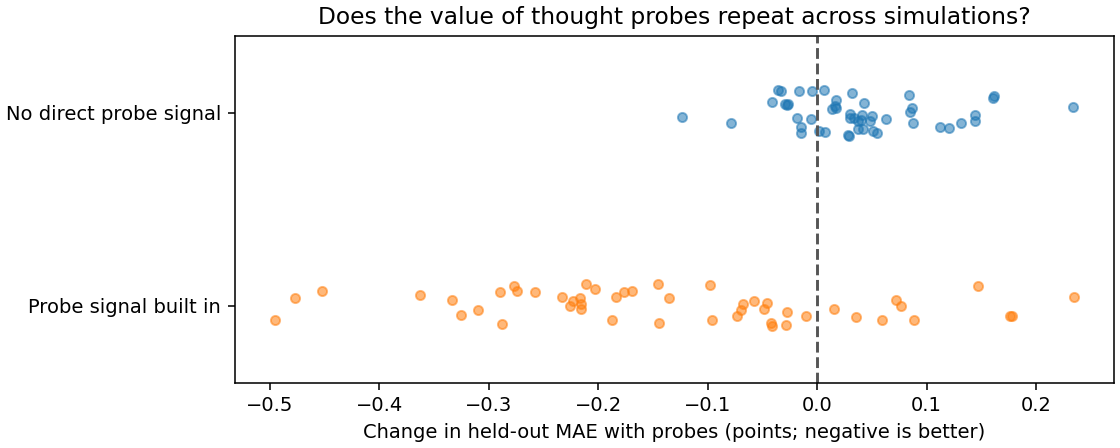

In [12]:
from contextlib import redirect_stdout
from io import StringIO

scenario_labels = {0: 'No direct probe signal', 24: 'Probe signal built in'}
differences = {}
for signal, label in scenario_labels.items():
    changes = []
    for seed in range(1000, 1050):
        records = simulate(probe_signal=signal, seed=seed)
        for row in records:
            row['split'] = 'development' if row['batch'] <= 14 else 'held_out'
        with redirect_stdout(StringIO()):
            errors = evaluate(records)
        changes.append(errors['Quiz + probes'] - errors['Pre + post'])
    differences[signal] = changes
    improved = sum(change < 0 for change in changes)
    print(f'{label}: helped in {improved}/{len(changes)} runs; '
          f'mean change {mean(changes):+.3f} points; '
          f'range {min(changes):+.3f} to {max(changes):+.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2), layout='constrained')
for level, (signal, label) in enumerate(scenario_labels.items()):
    spread = np.random.default_rng(signal).uniform(-0.12, 0.12, len(differences[signal]))
    ax.scatter(differences[signal], level + spread, alpha=0.55, s=22)
ax.axvline(0, color='#555555', linestyle='--')
ax.set(yticks=[0, 1], yticklabels=list(scenario_labels.values()), ylim=(-0.4, 1.4),
       xlabel='Change in held-out MAE with probes (points; negative is better)',
       title='Does the value of thought probes repeat across simulations?')
ax.invert_yaxis()
plt.show()

## Phase 3 — Simulate a refresher scheduling policy

**Question:** With only two early refresher slots for six new batches, does ranking batches by their forecast improve simulated retention compared with usual timing, a lottery, or ranking batches by their immediate post-test averages? Each early-slot rule has the same two slots.

All batches receive the same refresher: early means day 14; usual means day 28. All take a follow-up quiz on day 42. This is a simulation, not an LMS integration or a recommendation for real workers.

In [13]:
from collections import Counter
from random import Random
from statistics import mean

import numpy as np


def score(value):
    return round(min(100, max(0, value)))


def simulate(probe_signal, seed=510):
    rng = Random(seed)
    rows = []
    for batch in range(1, 21):
        training_shift = rng.gauss(0, 3)
        retention_shift = rng.gauss(0, 4)
        interruption_rate = rng.uniform(0.05, 0.18)
        for _ in range(24):
            preparation = rng.gauss(0, 1)
            propensity = rng.uniform(0.05, 0.60)
            pre = score(64 + 12 * preparation + rng.gauss(0, 8))
            post = score(78 + 10 * preparation + training_shift + rng.gauss(0, 8))
            delayed = score(
                0.8 * post + 0.2 * pre - 3 + retention_shift
                + rng.gauss(0, 7) - probe_signal * (propensity - 0.325)
            )
            responses = Counter()
            for _ in rng.sample(range(2, 10), 2):
                draw = rng.random()
                if draw < 0.12:
                    response = 'skipped'
                elif draw < 0.17:
                    response = 'unsure'
                elif draw < 0.17 + interruption_rate:
                    response = 'interrupted'
                elif draw < 0.17 + interruption_rate + propensity:
                    response = 'unrelated'
                else:
                    response = 'task-related'
                responses[response] += 1
            rows.append({
                'worker': len(rows) + 1, 'batch': batch,
                'pre': pre, 'post': post, 'delayed': delayed,
                'unrelated': responses['unrelated'],
                'interrupted': responses['interrupted'],
                'missing': responses['skipped'] + responses['unsure'],
            })
    return rows

## 1. Forecast before scheduling

We reuse the Phase 2 generator with a new seed and fit the pre/post quiz model only. Thought probes are not required: their added value was small and inconsistent in Phase 2. The generator still emits them for compatibility, but scheduling never reads them. Batch IDs group workers; they are not predictors. The delayed quiz is used to train on historical batches only. New batch choices use the mean of clipped forecasts, not actual delayed scores.

In [14]:
from itertools import combinations

rows = simulate(probe_signal=0, seed=730)
train = [row for row in rows if row['batch'] <= 14]
future = [row for row in rows if row['batch'] > 14]
assert {row['batch'] for row in train}.isdisjoint(row['batch'] for row in future)
assert {row['worker'] for row in train}.isdisjoint(row['worker'] for row in future)


def inputs(records):
    return np.array([[1, row['pre'], row['post']] for row in records])


weights, *_ = np.linalg.lstsq(inputs(train), [row['delayed'] for row in train], rcond=None)
predictions = np.clip(inputs(future) @ weights, 0, 100)
batches = sorted({row['batch'] for row in future})
forecasts = {
    batch: mean(pred for row, pred in zip(future, predictions, strict=True)
                if row['batch'] == batch)
    for batch in batches
}
early_slots = 2
priority = set(sorted(batches, key=lambda batch: (forecasts[batch], batch))[:early_slots])
lotteries = list(combinations(batches, early_slots))
assert len(priority) == early_slots and len(lotteries) == 15
for batch in sorted(forecasts, key=lambda batch: (forecasts[batch], batch)):
    print(f"Batch {batch}: forecast {forecasts[batch]:.1f}; "
          f"{'early' if batch in priority else 'usual'}")

Batch 17: forecast 66.8; early
Batch 19: forecast 68.3; early
Batch 15: forecast 69.1; usual
Batch 16: forecast 69.1; usual
Batch 18: forecast 71.2; usual
Batch 20: forecast 72.8; usual


### 2. What the scheduling simulation assumes

We compare **usual timing for all**, **a lottery for two early slots**, and **two early slots for the batches with the lowest forecasts**. We also test a no-model rule: give the same two early slots to the batches with the lowest immediate post-test averages. The lottery is a fair comparison for the same number of early slots: we average all 15 possible pairs. Every batch gets the same refresher and takes the final quiz on day 42.

To create a fictional day-42 score under usual timing, we start with the simulated pre-refresher delayed score, add an assumed two-point gain, and allow for ordinary score variation. We then ask what happens if moving a session earlier (1) makes no difference, (2) helps lower-scoring batches more, or (3) makes scores two points worse before applying the score limits. These effects are **assumed, not learned from data**. The scheduling rule never sees the later scores when choosing slots.

We assume one trainer, 30 minutes per batch, and full attendance: **three trainer delivery hours and 72 total learner-hours** under every policy. Forecast-guided planning adds an illustrative ten staff minutes. Moving the same session earlier does not save delivery time.

In [15]:
rng = Random(731)
usual_scores = [row['delayed'] + 2 + rng.gauss(0, 3) for row in future]
underlying = {
    batch: mean(row['delayed'] for row in future if row['batch'] == batch)
    for batch in batches
}
midpoint = mean(underlying.values())


def followup(early, effects):
    return mean(
        min(100, max(0, value + (effects[row['batch']] if row['batch'] in early else 0)))
        for row, value in zip(future, usual_scores, strict=True)
    )


usual = followup(set(), {})
scenarios = {
    'No timing effect': dict.fromkeys(batches, 0),
    'Earlier helps lower-score batches more': {
        batch: max(0, 2 + 0.6 * (midpoint - underlying[batch])) for batch in batches
    },
    'Earlier is less effective': dict.fromkeys(batches, -2),
}
post_priority = set(sorted(batches, key=lambda batch: (
    mean(row['post'] for row in future if row['batch'] == batch), batch
))[:early_slots])
print(f'Post-test-only early slots: {sorted(post_priority)}; forecast-guided: {sorted(priority)}')
policy_results = {}
for label, effects in scenarios.items():
    lottery = mean(followup(set(draw), effects) for draw in lotteries)
    guided = followup(priority, effects)
    post_only = followup(post_priority, effects)
    policy_results[label] = (usual, lottery, guided, post_only)
    print(f'{label}: usual {usual:.2f}, lottery {lottery:.2f}, guided {guided:.2f}, post-test rule {post_only:.2f}')

assert all(followup(set(draw), scenarios['No timing effect']) == usual for draw in lotteries)
trainer_hours = len(batches) * 30 / 60
learner_hours = len(future) * 30 / 60
print(f'Trainer delivery: {trainer_hours:.1f} hours; learner time: {learner_hours:.1f} hours (all policies)')
print('Extra model-guided planning: 10 staff minutes (illustrative)')

Post-test-only early slots: [17, 19]; forecast-guided: [17, 19]
No timing effect: usual 70.60, lottery 70.60, guided 70.60, post-test rule 70.60
Earlier helps lower-score batches more: usual 70.60, lottery 71.68, guided 72.12, post-test rule 72.12
Earlier is less effective: usual 70.60, lottery 69.95, guided 69.95, post-test rule 69.95
Trainer delivery: 3.0 hours; learner time: 72.0 hours (all policies)
Extra model-guided planning: 10 staff minutes (illustrative)


## 3. What was and wasn’t done

**Built:** an offline prototype connecting a delayed-score forecast to a fixed-capacity scheduling rule. Usual timing shows whether moving sessions earlier helps under the assumptions; the lottery shows whether the forecast adds value over allocating the same early slots without it.

**Not done:** no real workers were assigned; no effect or resource saving was measured. Lower predicted scores are not evidence that earlier timing helps. All policies deliver the same number of sessions, so the model cannot save delivery time here. To test real value, compare policies prospectively across batches, use a common follow-up date, and track attendance, staff time and learner time.

**Simpler rule, same result:** Ranking by immediate post-test averages selected the same two batches as the forecast. In this run the model added planning time without changing the decision or simulated outcomes. That is a result for these six batches, not a general claim about forecasting.

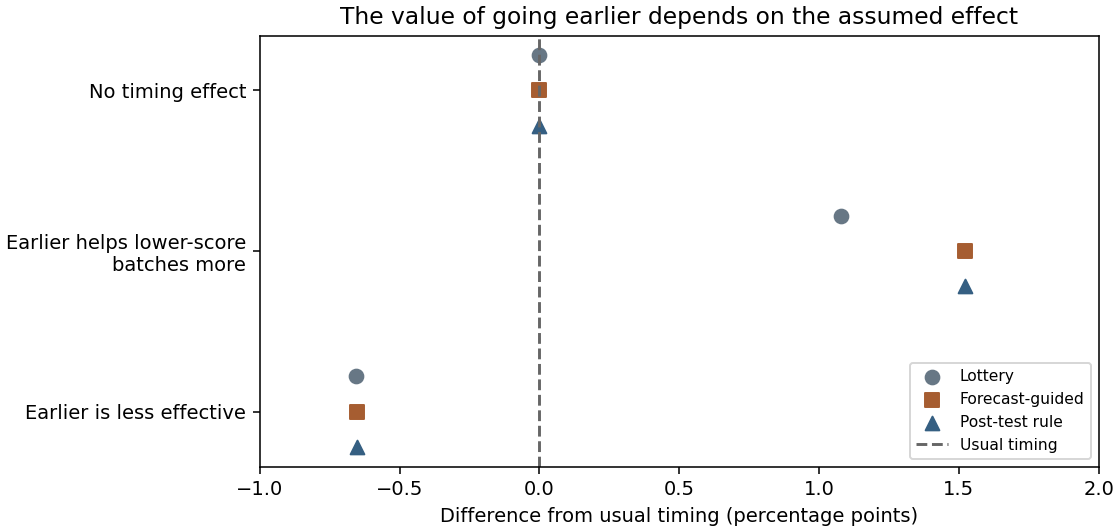

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.8), layout='constrained')
scenario_names = ['No timing effect', 'Earlier helps lower-score\nbatches more',
                  'Earlier is less effective']
for offset, policy_index, label in [(-0.22, 1, 'Lottery'), (0, 2, 'Forecast-guided'),
                                    (0.22, 3, 'Post-test rule')]:
    differences = [outcomes[policy_index] - outcomes[0]
                   for outcomes in policy_results.values()]
    ax.scatter(differences, [index + offset for index in range(len(scenario_names))],
               label=label, color={1: '#677785', 2: '#a65d31', 3: '#355f82'}[policy_index], marker={1: 'o', 2: 's', 3: '^'}[policy_index], s=50)
ax.axvline(0, color='#666666', linestyle='--', label='Usual timing')
ax.set(yticks=range(len(scenario_names)), yticklabels=scenario_names, xlim=(-1, 2),
       xlabel='Difference from usual timing (percentage points)',
       title='The value of going earlier depends on the assumed effect')
ax.invert_yaxis()
ax.legend(loc='lower right', fontsize=8)
plt.show()

**Read the chart:** Zero means no difference from usual timing. The post-test rule and forecast selected the same batches, so their markers share the same horizontal position. Vertical offsets just separate markers.

---

## Extension · Can practice signals predict a thought report?

**Different outcome:** This predicts a report at the upcoming prompt, not a later quiz score.

## Extension: Can earlier practice signals predict the next thought report?

This is a separate question from predicting delayed quiz scores. Here the outcome is the worker’s **report at the upcoming prompt**, if it describes task-related or unrelated thoughts. We don’t skip ahead to find a later usable response. Skipped, unsure, and external-interruption responses are excluded, not treated as on-task. Results apply only to these two clear response categories.

We simulate two streams on the same clock: **practice response times** and an illustrative **gaze-away indicator**. The model summarises only the preceding 30 seconds, excluding events at or after the prompt. Both streams share a simulated momentary state with the probe response; this deliberately gives them a chance to help. Looking away is not proof of mind wandering, and no real gaze is collected.

A majority-class baseline always guesses the most common training response. Two simple classifiers learn a score from the training data and predict “unrelated” at a fixed cutoff of 0.5. We compare their F1 scores (which combine how often flags are right and how many unrelated reports they catch) on the same six unseen batches.

A response-time event is timestamped at **submission**, when its full duration becomes available. An answer started before a prompt but submitted after it is excluded. We repeat the comparison across 50 seeds, including a no-gaze-signal scenario and an illustrative selective-exclusion scenario (45% of unrelated versus 20% of task-related reports excluded). That last check evaluates the remaining reports, not the unobserved responses. The fixed cutoff is not tuned on test batches.

In [17]:
def simulate_stream_examples(seed=825, gaze_signal=True, selective_skip=False):
    rng = Random(seed)
    examples = []
    for batch in range(1, 21):
        batch_pace = rng.gauss(0, 1)
        for learner in range(24):
            usual_pace = 10 + batch_pace + rng.gauss(0, 2)
            for probe_time in (60, 120, 180, 240):
                state = rng.gauss(0, 1)
                interaction = [(probe_time + offset, max(0, usual_pace + 2 * state + rng.gauss(0, 3)))
                               for offset in (-25, -15, -5, 0, 5)]
                gaze = [(probe_time + offset, int((state if gaze_signal else 0) + rng.gauss(0, 1.4) > 0.6))
                        for offset in (-28, -18, -8, -2, 0, 4)]
                draw = rng.random()
                label = int(state + rng.gauss(0, 1) > 0.6)
                if draw < (0.45 if selective_skip and label else 0.20):
                    continue
                examples.append((batch, label, recent_mean(interaction, probe_time),
                                 recent_mean(gaze, probe_time)))
    return np.array(examples)


def recent_mean(events, probe_time):
    return mean(value for available_at, value in events
                if probe_time - 30 <= available_at < probe_time)


assert recent_mean([(69, 900), (70, 2), (99, 4), (100, 900), (101, 900)], 100) == 3
before_prompt = [(90, 4)]
started_before_but_submitted_after = (103, 103 - 95)
assert recent_mean(before_prompt + [started_before_but_submitted_after], 100) == 4


def stream_f1(stream_examples, verbose=False):
    scores = {}
    stream_train = stream_examples[stream_examples[:, 0] <= 14]
    stream_test = stream_examples[stream_examples[:, 0] > 14]
    assert not set(stream_train[:, 0]) & set(stream_test[:, 0])
    observed_reports = stream_test[:, 1]
    if verbose:
        print(f'{len(stream_train)} training reports; {len(stream_test)} test reports; '
          f'{observed_reports.mean():.1%} unrelated in test')
    if verbose:
        print('Model                     Accuracy   Precision   Recall      F1')
    for name, end in [('Majority baseline', 2), ('Interaction only', 3), ('Interaction + gaze', 4)]:
        if end == 2:
            predicted = np.full(len(stream_test), stream_train[:, 1].mean() > 0.5)
        else:
            train_inputs = np.column_stack((np.ones(len(stream_train)), stream_train[:, 2:end]))
            test_inputs = np.column_stack((np.ones(len(stream_test)), stream_test[:, 2:end]))
            coefficients = np.linalg.lstsq(train_inputs, stream_train[:, 1], rcond=None)[0]
            predicted = test_inputs @ coefficients >= 0.5
        hits = np.sum(predicted & (observed_reports == 1))
        precision = hits / max(1, predicted.sum())
        recall = hits / max(1, observed_reports.sum())
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
        scores[name] = f1
        if verbose:
            print(f'{name:24} {np.mean(predicted == observed_reports):9.1%} '
              f'{precision:11.1%} {recall:8.1%} {f1:7.3f}')
    return scores


stream_f1(simulate_stream_examples(), verbose=True)
print('\nSensitivity across 50 paired seeds per scenario (F1 difference: combined minus interaction)')
gaze_f1_changes = {}
for label, gaze_signal, selective_skip in (
    ('Shared signal', True, False),
    ('No gaze signal', False, False),
    ('Shared signal + selective exclusion', True, True),
):
    changes = []
    for seed in range(2000, 2050):
        scores = stream_f1(simulate_stream_examples(seed, gaze_signal, selective_skip))
        changes.append(scores['Interaction + gaze'] - scores['Interaction only'])
    gaze_f1_changes[label] = changes
    print(f'{label}: mean {mean(changes):+.3f}; improved in {sum(change > 0 for change in changes)}/50')

1098 training reports; 465 test reports; 34.0% unrelated in test
Model                     Accuracy   Precision   Recall      F1
Majority baseline            66.0%        0.0%     0.0%   0.000
Interaction only             69.9%       66.7%    22.8%   0.340
Interaction + gaze           74.8%       69.9%    45.6%   0.552

Sensitivity across 50 paired seeds per scenario (F1 difference: combined minus interaction)
Shared signal: mean +0.171; improved in 50/50
No gaze signal: mean +0.003; improved in 24/50
Shared signal + selective exclusion: mean +0.253; improved in 50/50


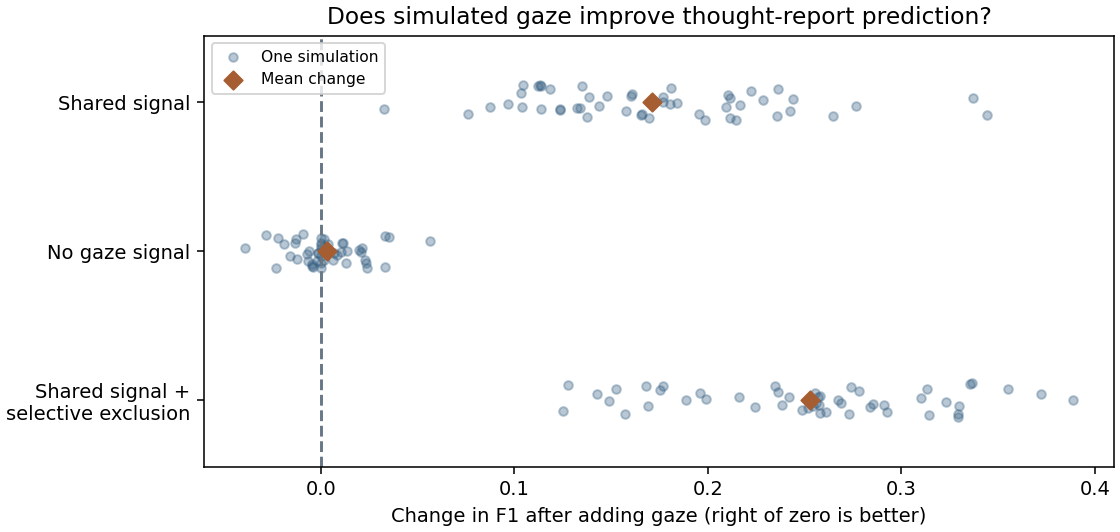

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.8), layout='constrained')
gaze_labels = ['Shared signal', 'No gaze signal', 'Shared signal +\nselective exclusion']
for index, changes in enumerate(gaze_f1_changes.values()):
    spread = np.random.default_rng(index).uniform(-0.12, 0.12, len(changes))
    ax.scatter(changes, index + spread, color='#355f82', alpha=0.35, s=20,
               label='One simulation' if index == 0 else None)
    ax.scatter(mean(changes), index, color='#a65d31', marker='D', s=44, zorder=3,
               label='Mean change' if index == 0 else None)
ax.axvline(0, color='#677785', linestyle='--')
ax.set(yticks=range(3), yticklabels=gaze_labels, ylim=(-0.45, 2.45),
       xlabel='Change in F1 after adding gaze (right of zero is better)',
       title='Does simulated gaze improve thought-report prediction?')
ax.invert_yaxis()
ax.legend(loc='upper left', fontsize=8)
plt.show()

**Read the chart:** Each circle is one run; the diamond is the average. Without a gaze signal, the average change is near zero. The gain under selective exclusion applies only to retained reports.

## What a real pilot would need to establish

1. **Can we measure it?** Check whether workers understand the optional prompts, how often they skip, and whether the prompts interrupt practice.
2. **Does it improve the forecast?** Collect linked quiz scores from real batches and check whether thought reports improve forecasts on new batches by enough to justify collecting them.
3. **Does acting on the forecast help?** Compare forecast-guided timing with a fair alternative, assess both groups at the same time from initial training, and track retention, attendance, and staff and learner time.

**Bottom line:** Predicting a lower quiz score is not the same as predicting who benefits from an earlier refresher. This notebook demonstrates how to test both questions; it does not answer either for real workers.